In [3]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv
import os

In [4]:
load_dotenv()
api_key = os.environ.get("GEMINI_API_KEY")

In [5]:
llm = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite",
    api_key = api_key,
    # temperature = 0.4
)

In [6]:
class QA_state(TypedDict):
    question : str
    answer : str

In [13]:
def QA_node(state : QA_state) -> QA_state:

    ques = state['question']
    ans = llm.invoke(ques)
    state['answer'] = ans.text

    return state

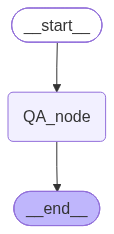

In [14]:
graph = StateGraph(QA_state)

graph.add_node("QA_node", QA_node)

graph.add_edge(START, "QA_node")
graph.add_edge("QA_node", END)

workflow = graph.compile()
workflow

In [15]:
initial_state = {"question" : "Hello How are you"}
final_state = workflow.invoke(initial_state)
final_state

{'question': 'Hello How are you',
 'answer': "Hello! I'm doing well, thank you for asking. How can I help you today?"}